# 01 — Analyse exploratoire des données (EDA)

**Projet :** Smart Maintenance AI — maintenance prédictive des machines industrielles

## Objectif du notebook

Ce notebook présente le dataset **NASA C-MAPSS (sous-ensemble FD001)** et réalise une analyse
exploratoire complète : structure des données, qualité, distribution des variables,
évolution des capteurs dans le temps, corrélations et identification des capteurs inutiles.

Les conclusions de cette analyse serviront à choisir les capteurs utilisés par les modèles.

## 1. Présentation du dataset

### Origine
Le dataset **C-MAPSS** (*Commercial Modular Aero-Propulsion System Simulation*) a été publié par le
**Prognostics Center of Excellence de la NASA Ames** (Saxena et al., 2008). Il s'agit de données
**simulées** de moteurs d'avion de type turboréacteur à double flux (*turbofan*).
C'est l'un des jeux de données de référence en maintenance prédictive.

### Les moteurs étudiés (FD001)
- **100 moteurs** dans le jeu d'entraînement et **100 moteurs** dans le jeu de test.
- **1 seule condition de fonctionnement** (niveau de la mer).
- **1 seul mode de panne** : dégradation du compresseur haute pression (HPC).

### Les cycles de fonctionnement
Chaque ligne correspond à **un cycle de fonctionnement** (un vol) d'un moteur.
- Dans le **jeu d'entraînement**, chaque moteur est suivi **jusqu'à sa panne** : le dernier cycle est le cycle de panne.
- Dans le **jeu de test**, la série est **coupée avant la panne**. Le fichier `RUL_FD001.txt` donne
  le nombre réel de cycles restants après le dernier cycle observé.

### Les colonnes (26 au total)
| Colonnes | Signification |
|---|---|
| `unit_id` | Identifiant du moteur |
| `cycle` | Numéro du cycle |
| `op_setting_1` à `op_setting_3` | Paramètres opérationnels (altitude, Mach, angle de manette des gaz) |
| `sensor_1` à `sensor_21` | Mesures des 21 capteurs |

### Les 21 capteurs
| Capteur | Mesure | Capteur | Mesure |
|---|---|---|---|
| sensor_1 | T2 – température entrée ventilateur | sensor_12 | phi – rapport carburant / Ps30 |
| sensor_2 | T24 – température sortie LPC | sensor_13 | NRf – vitesse corrigée ventilateur |
| sensor_3 | T30 – température sortie HPC | sensor_14 | NRc – vitesse corrigée cœur |
| sensor_4 | T50 – température sortie LPT | sensor_15 | BPR – taux de dilution |
| sensor_5 | P2 – pression entrée ventilateur | sensor_16 | farB – rapport carburant/air brûleur |
| sensor_6 | P15 – pression conduit de dérivation | sensor_17 | htBleed – enthalpie de prélèvement |
| sensor_7 | P30 – pression sortie HPC | sensor_18 | Nf_dmd – vitesse ventilateur demandée |
| sensor_8 | Nf – vitesse physique ventilateur | sensor_19 | PCNfR_dmd – vitesse corrigée demandée |
| sensor_9 | Nc – vitesse physique cœur | sensor_20 | W31 – débit de refroidissement HPT |
| sensor_10 | epr – rapport de pression moteur | sensor_21 | W32 – débit de refroidissement LPT |
| sensor_11 | Ps30 – pression statique sortie HPC | | |

### La dégradation progressive et la notion de RUL
Chaque moteur démarre avec un niveau d'usure initial inconnu, puis une **défaillance se développe
progressivement** jusqu'à la panne. Les capteurs reflètent cette dégradation.

Le **RUL** (*Remaining Useful Life*) est la **durée de vie restante** d'un moteur,
exprimée en nombre de cycles avant la panne :

$$RUL = \text{dernier cycle du moteur} - \text{cycle actuel}$$

Prédire le RUL permet de planifier la maintenance **avant** la panne.

## 2. Importation des bibliothèques

In [1]:
# Importation des bibliothèques
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Accès au fichier features.py (partagé avec le backend)
sys.path.append("../backend")
from features import load_cmapss_file

# Style des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

## 3. Chargement des données

In [2]:
# Chargement des fichiers NASA
train_data = load_cmapss_file("../data/train_FD001.txt")
test_data = load_cmapss_file("../data/test_FD001.txt")
rul_test = pd.read_csv("../data/RUL_FD001.txt", header=None, names=["RUL"])

# Affichage des premières lignes
train_data.head()

,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 4. Dimensions et types des variables

In [3]:
# Dimensions des jeux de données
print("Jeu d'entraînement :", train_data.shape)
print("Jeu de test        :", test_data.shape)
print("Fichier RUL        :", rul_test.shape)

# Nombre de moteurs
print("\nMoteurs (entraînement) :", train_data["unit_id"].nunique())
print("Moteurs (test)         :", test_data["unit_id"].nunique())

Jeu d'entraînement : (20631, 26)
Jeu de test        : (13096, 26)
Fichier RUL        : (100, 1)

Moteurs (entraînement) : 100
Moteurs (test)         : 100


In [4]:
# Types des variables
print(train_data.dtypes.value_counts())
train_data.dtypes.head(8)

float64    22
int64       4
Name: count, dtype: int64


unit_id           int64
cycle             int64
op_setting_1    float64
op_setting_2    float64
op_setting_3    float64
sensor_1        float64
sensor_2        float64
sensor_3        float64
dtype: object

**Interprétation :** toutes les variables sont numériques. `unit_id` et `cycle` sont des entiers,
les paramètres opérationnels et les capteurs sont des réels.

## 5. Statistiques descriptives

In [5]:
# Statistiques descriptives (transposées pour une meilleure lecture)
train_data.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
unit_id,20631.0,51.5066,29.2276,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.8079,68.8810,1.0000,52.0000,104.0000,156.0000,362.0000
op_setting_1,20631.0,-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,20631.0,0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,20631.0,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.5231,6.1311,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.9338,9.0006,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200


## 6. Valeurs manquantes et doublons

In [6]:
# Vérification des valeurs manquantes
missing_values = train_data.isnull().sum()
print("Valeurs manquantes (entraînement) :", missing_values.sum())
print("Valeurs manquantes (test)         :", test_data.isnull().sum().sum())

# Recherche des lignes dupliquées
print("Doublons (entraînement) :", train_data.duplicated().sum())
print("Doublons (test)         :", test_data.duplicated().sum())

Valeurs manquantes (entraînement) : 0
Valeurs manquantes (test)         : 0
Doublons (entraînement) : 0
Doublons (test)         : 0


**Interprétation :** le dataset ne contient **aucune valeur manquante** et **aucun doublon**.
Aucune imputation n'est donc nécessaire.

## 7. Durée de vie des moteurs

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


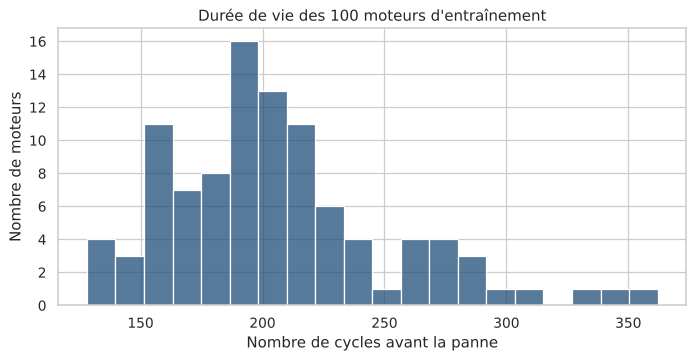

In [7]:
# Nombre de cycles de chaque moteur (= durée de vie totale dans le jeu d'entraînement)
cycles_per_engine = train_data.groupby("unit_id")["cycle"].max()

print(cycles_per_engine.describe().round(1))

plt.figure(figsize=(9, 4))
sns.histplot(cycles_per_engine, bins=20, color="#1f4e79")
plt.title("Durée de vie des 100 moteurs d'entraînement")
plt.xlabel("Nombre de cycles avant la panne")
plt.ylabel("Nombre de moteurs")
plt.show()

**Interprétation :** la durée de vie varie fortement d'un moteur à l'autre (environ 128 à 362 cycles).
Il est donc impossible de prédire le RUL avec une simple moyenne : il faut exploiter les capteurs.

## 8. Identification des capteurs constants ou peu pertinents

Un capteur dont la valeur ne varie presque pas ne contient **aucune information** sur la dégradation.

In [8]:
# Écart-type de chaque variable
sensor_and_settings = []
for column in train_data.columns:
    if column.startswith("sensor_") or column.startswith("op_setting_"):
        sensor_and_settings.append(column)

standard_deviations = train_data[sensor_and_settings].std().sort_values()
print(standard_deviations.round(5))

sensor_1         0.00000
op_setting_3     0.00000
sensor_10        0.00000
sensor_19        0.00000
sensor_18        0.00000
sensor_16        0.00000
sensor_5         0.00000
op_setting_2     0.00029
sensor_6         0.00139
op_setting_1     0.00219
sensor_15        0.03751
sensor_8         0.07099
sensor_13        0.07192
sensor_21        0.10825
sensor_20        0.18075
sensor_11        0.26709
sensor_2         0.50005
sensor_12        0.73755
sensor_7         0.88509
sensor_17        1.54876
sensor_3         6.13115
sensor_4         9.00060
sensor_14       19.07618
sensor_9        22.08288
dtype: float64


In [9]:
# Nombre de valeurs différentes pour chaque variable
unique_counts = train_data[sensor_and_settings].nunique().sort_values()
print(unique_counts)

sensor_1           1
op_setting_3       1
sensor_5           1
sensor_10          1
sensor_18          1
sensor_19          1
sensor_16          1
sensor_6           2
sensor_17         13
op_setting_2      13
sensor_8          53
sensor_13         56
sensor_20        120
op_setting_1     158
sensor_11        159
sensor_2         310
sensor_12        427
sensor_7         513
sensor_15       1918
sensor_3        3012
sensor_4        4051
sensor_21       4745
sensor_14       6078
sensor_9        6403
dtype: int64


In [10]:
# Liste des variables constantes ou quasi constantes
constant_columns = []
for column in sensor_and_settings:
    if train_data[column].std() < 0.001 or train_data[column].nunique() <= 2:
        constant_columns.append(column)

print("Variables constantes ou quasi constantes :", constant_columns)

Variables constantes ou quasi constantes : ['op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


**Interprétation :**
- `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19` et `op_setting_3`
  sont **constants** (une seule condition de vol dans FD001).
- `sensor_6` ne prend que 2 valeurs : il est quasi constant.
- `op_setting_2` est détecté par le seuil (écart-type < 0,001) et `op_setting_1` varie très peu :
  ce sont de petites variations autour d'une seule condition de vol.

Ces variables (capteurs constants et 3 paramètres opérationnels) seront **supprimées** lors du prétraitement.

## 9. Distribution des capteurs

Capteurs utiles : 14


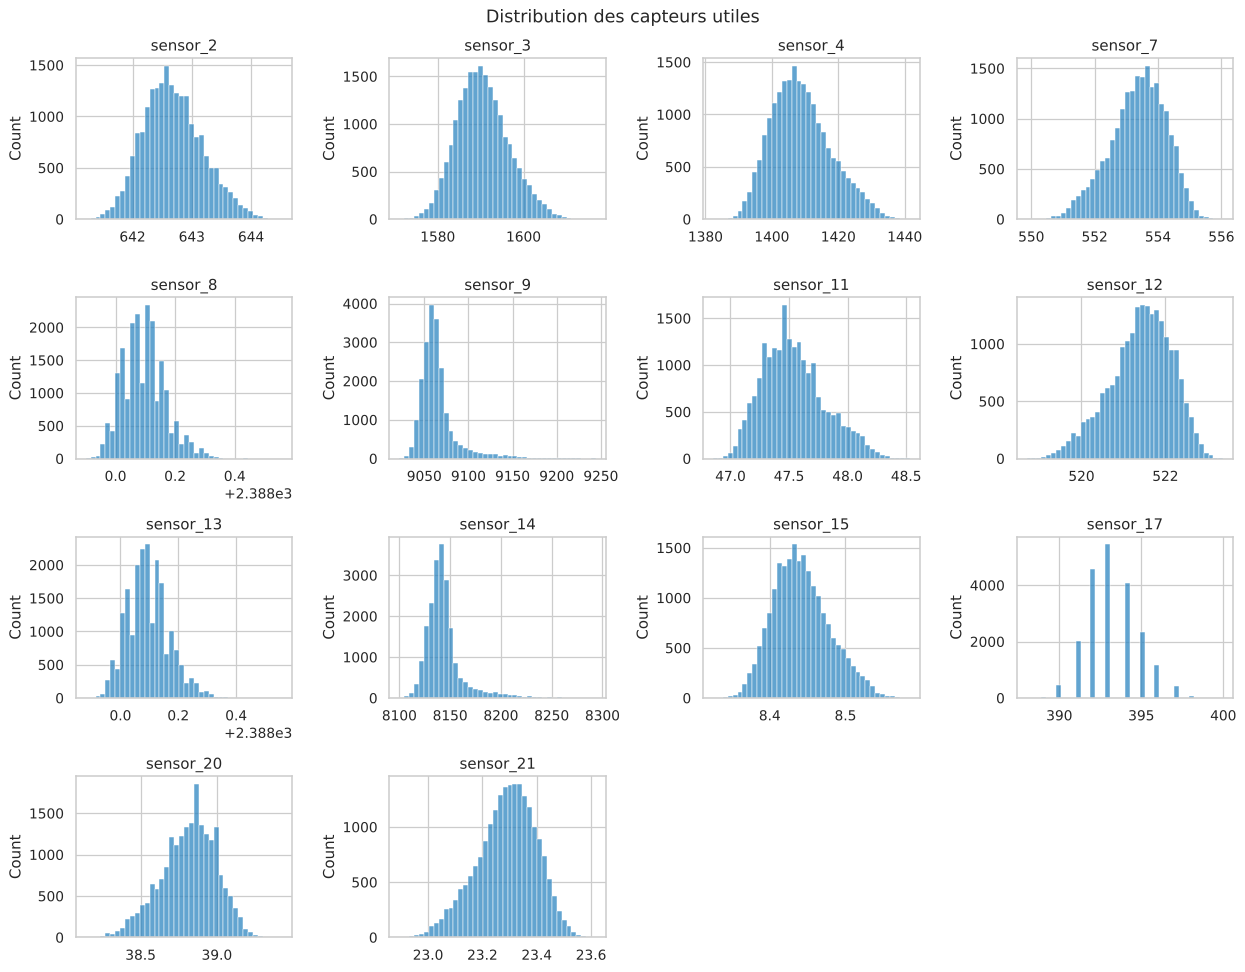

In [11]:
# Capteurs non constants
useful_sensors = []
for column in train_data.columns:
    if column.startswith("sensor_") and column not in constant_columns:
        useful_sensors.append(column)

print("Capteurs utiles :", len(useful_sensors))

# Histogramme de chaque capteur utile
fig, axes = plt.subplots(4, 4, figsize=(14, 11))
axes = axes.flatten()
for index, sensor in enumerate(useful_sensors):
    sns.histplot(train_data[sensor], bins=40, ax=axes[index], color="#2e86c1")
    axes[index].set_title(sensor)
    axes[index].set_xlabel("")
for index in range(len(useful_sensors), len(axes)):
    axes[index].axis("off")
plt.suptitle("Distribution des capteurs utiles", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation :** la plupart des capteurs ont une distribution proche d'une loi normale
légèrement asymétrique : la queue de distribution correspond aux cycles proches de la panne.

## 10. Évolution des capteurs au cours du temps

On trace l'évolution de quelques capteurs pour 5 moteurs.

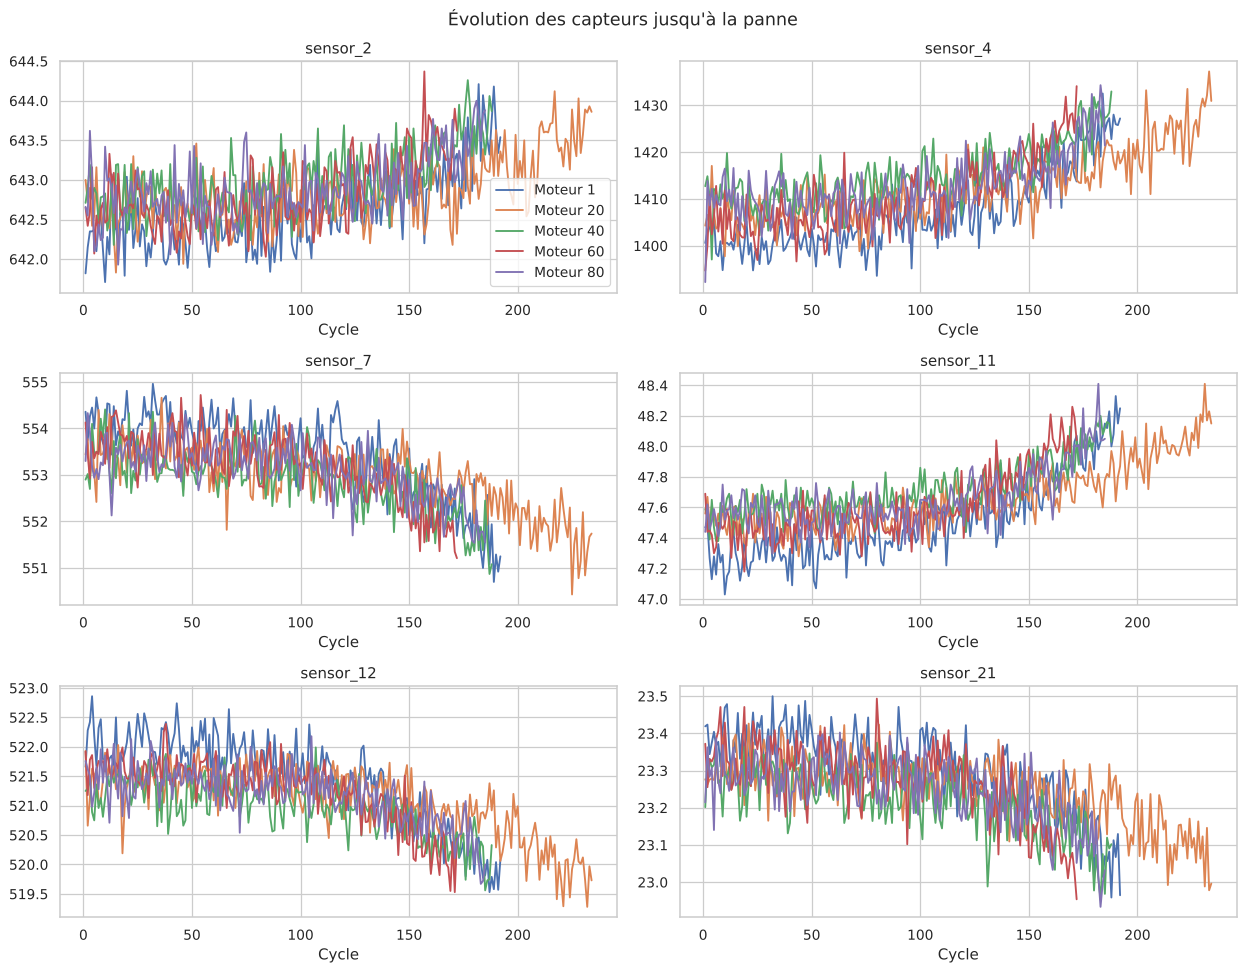

In [12]:
# Moteurs choisis pour la visualisation
engines_to_plot = [1, 20, 40, 60, 80]
sensors_to_plot = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_21"]

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()
for index, sensor in enumerate(sensors_to_plot):
    for engine in engines_to_plot:
        engine_data = train_data[train_data["unit_id"] == engine]
        axes[index].plot(engine_data["cycle"], engine_data[sensor], label="Moteur " + str(engine))
    axes[index].set_title(sensor)
    axes[index].set_xlabel("Cycle")
axes[0].legend()
plt.suptitle("Évolution des capteurs jusqu'à la panne", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation :** les capteurs sont **bruités**, mais une **tendance nette** apparaît à
l'approche de la panne : certains capteurs augmentent (`sensor_2`, `sensor_4`, `sensor_11`),
d'autres diminuent (`sensor_7`, `sensor_12`, `sensor_21`).
Le bruit justifie le calcul de **moyennes mobiles** dans le prétraitement.

## 11. Analyse de la dégradation des moteurs

Pour comparer tous les moteurs entre eux, on aligne les courbes sur le **RUL** (cycles avant la panne)
au lieu du numéro de cycle.

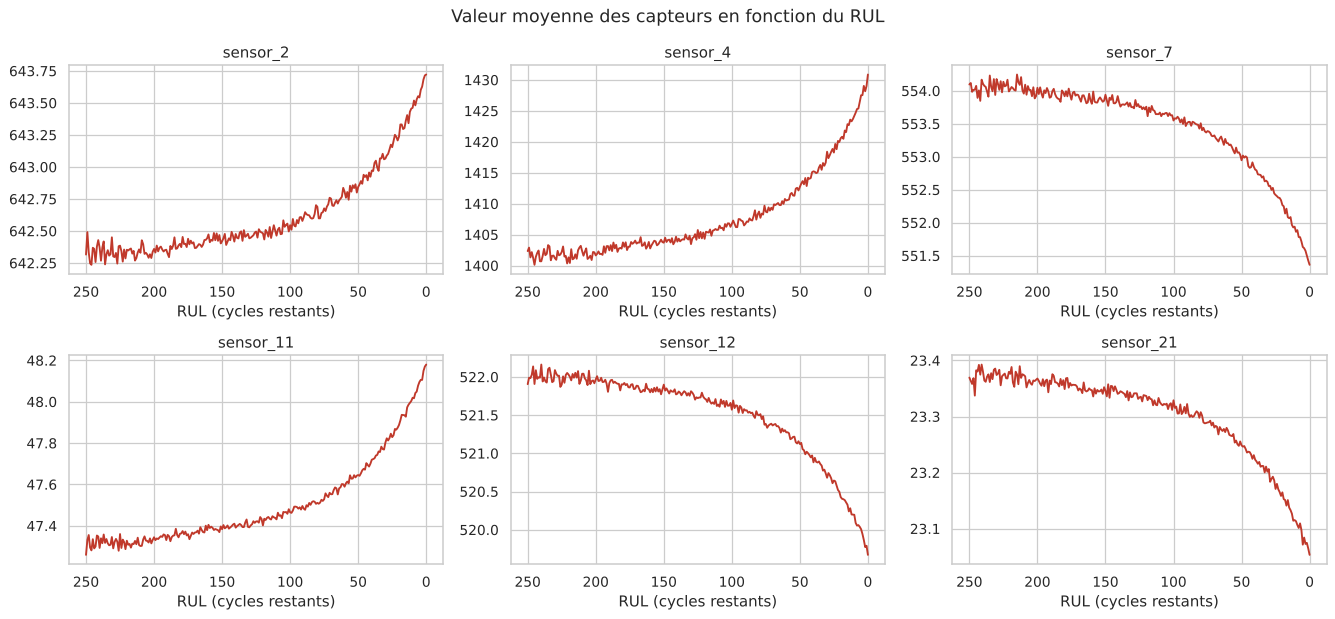

In [13]:
# Calcul du RUL réel (non plafonné) pour l'analyse
last_cycle = train_data.groupby("unit_id")["cycle"].transform("max")
train_data["RUL"] = last_cycle - train_data["cycle"]

# Moyenne de chaque capteur en fonction du RUL (sur tous les moteurs)
mean_by_rul = train_data.groupby("RUL")[sensors_to_plot].mean()
mean_by_rul = mean_by_rul[mean_by_rul.index <= 250]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()
for index, sensor in enumerate(sensors_to_plot):
    axes[index].plot(mean_by_rul.index, mean_by_rul[sensor], color="#c0392b")
    axes[index].invert_xaxis()
    axes[index].set_title(sensor)
    axes[index].set_xlabel("RUL (cycles restants)")
plt.suptitle("Valeur moyenne des capteurs en fonction du RUL", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation :** les capteurs restent **stables** tant que le RUL est élevé (environ au-delà
de 120-130 cycles), puis évoluent de plus en plus vite jusqu'à la panne.
Ce comportement justifie l'utilisation d'un **RUL plafonné** (par exemple à 125 cycles) :
au début de sa vie, un moteur est simplement « en bonne santé » et les capteurs ne permettent
pas de distinguer un RUL de 200 d'un RUL de 150.

## 12. Matrice de corrélation

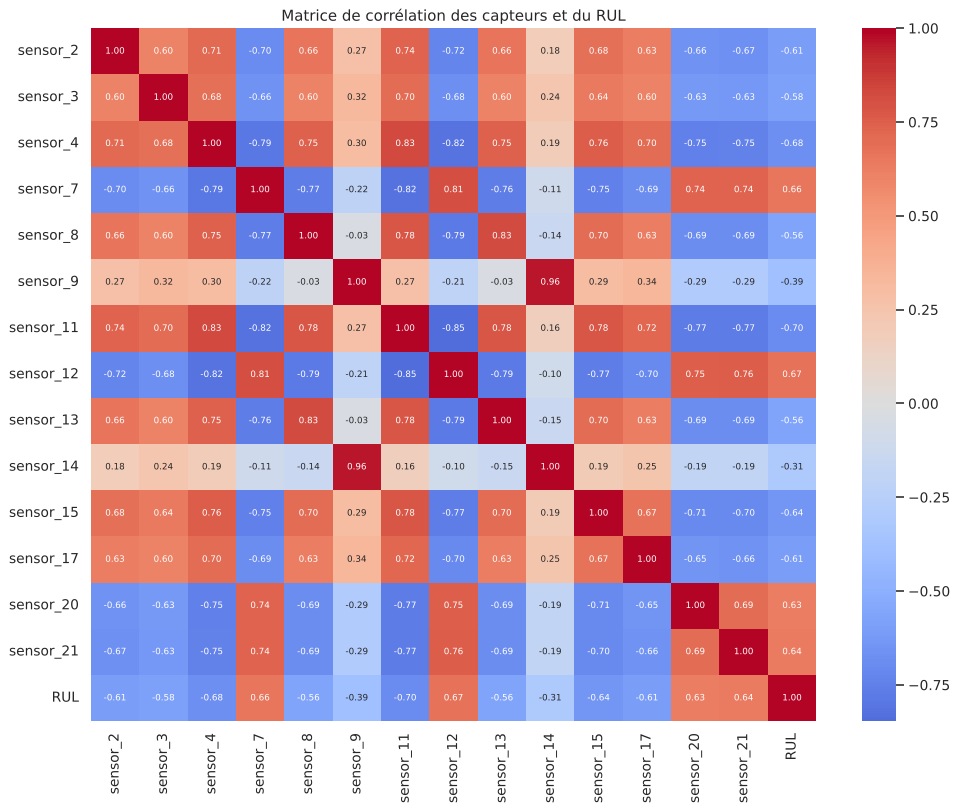

In [14]:
# Matrice de corrélation entre les capteurs utiles et le RUL
correlation_matrix = train_data[useful_sensors + ["RUL"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Matrice de corrélation des capteurs et du RUL")
plt.show()

sensor_11   -0.696
sensor_4    -0.679
sensor_15   -0.643
sensor_2    -0.606
sensor_17   -0.606
sensor_3    -0.585
sensor_8    -0.564
sensor_13   -0.563
sensor_9    -0.390
sensor_14   -0.307
sensor_20    0.629
sensor_21    0.636
sensor_7     0.657
sensor_12    0.672
Name: RUL, dtype: float64


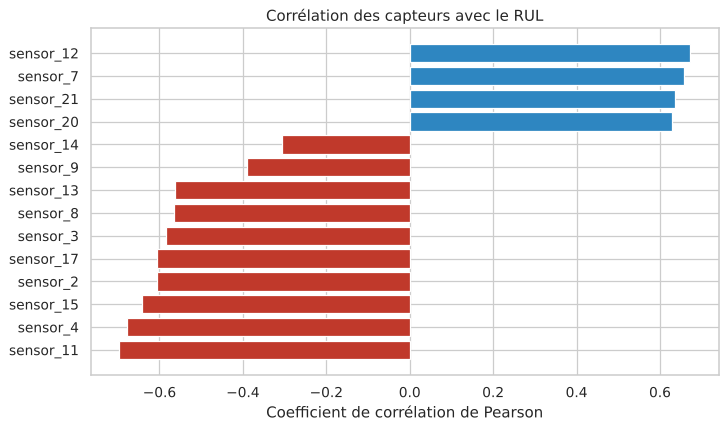

In [15]:
# Corrélation de chaque capteur avec le RUL (triée)
correlation_with_rul = correlation_matrix["RUL"].drop("RUL").sort_values()
print(correlation_with_rul.round(3))

plt.figure(figsize=(9, 5))
colors = []
for value in correlation_with_rul:
    if value < 0:
        colors.append("#c0392b")
    else:
        colors.append("#2e86c1")
plt.barh(correlation_with_rul.index, correlation_with_rul.values, color=colors)
plt.title("Corrélation des capteurs avec le RUL")
plt.xlabel("Coefficient de corrélation de Pearson")
plt.show()

**Interprétation :**
- Les capteurs `sensor_11`, `sensor_4`, `sensor_12`, `sensor_7`, `sensor_15`, `sensor_21`, `sensor_20`,
  `sensor_2` et `sensor_17` sont **fortement corrélés** au RUL (|r| > 0,6).
- Les capteurs dont la valeur **augmente** avec l'usure ont une corrélation négative avec le RUL,
  ceux qui **diminuent** ont une corrélation positive.
- `sensor_9` et `sensor_14` sont fortement corrélés entre eux (vitesses du cœur) et moins liés
  au RUL (|r| ≈ 0,3-0,4) : ils sont conservés car un modèle non linéaire peut les exploiter.

La corrélation de Pearson ne mesure que les relations **linéaires** : un capteur peu corrélé
peut tout de même être utile à un modèle non linéaire.

## 13. Aperçu du jeu de test

In [16]:
# Nombre de cycles observés pour chaque moteur de test
observed_cycles_test = test_data.groupby("unit_id")["cycle"].max()
print("Cycles observés par moteur de test :")
print(observed_cycles_test.describe().round(1))

print("\nRUL réel des moteurs de test (fichier RUL_FD001.txt) :")
print(rul_test["RUL"].describe().round(1))

Cycles observés par moteur de test :
count    100.0
mean     131.0
std       53.6
min       31.0
25%       88.8
50%      133.5
75%      164.2
max      303.0
Name: cycle, dtype: float64

RUL réel des moteurs de test (fichier RUL_FD001.txt) :
count    100.0
mean      75.5
std       41.8
min        7.0
25%       32.8
50%       86.0
75%      112.2
max      145.0
Name: RUL, dtype: float64


**Interprétation :** les séries de test sont coupées à des instants variés (de 31 à 303 cycles).
Le RUL réel à prédire va de 7 à 145 cycles.

## 14. Conclusion

- Le dataset est **propre** : pas de valeurs manquantes, pas de doublons.
- **7 capteurs constants** et les **3 paramètres opérationnels** n'apportent pas d'information
  et seront supprimés → **14 capteurs retenus** :
  `sensor_2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`.
- Les capteurs sont **bruités** → calcul de **moyennes mobiles**.
- La dégradation n'est visible qu'en fin de vie → utilisation d'un **RUL plafonné à 125 cycles**.
- Le jeu de test officiel sera **uniquement** utilisé pour l'évaluation finale.